# 02 — Pipeline predictivo: duración de ciclo de sueño
**Tipo de aprendizaje:** supervisado. **Tarea:** regresión. **Modelo:** regresión lineal múltiple.

**AVISO:** Se generan **180 registros sintéticos** para practicar. La infografía no proporciona un dataset individual de 152 bebés. No interpretes las métricas como validación clínica.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

rng=np.random.default_rng(2026)
n=180
edad=rng.integers(0,13,n)
lactancia=rng.choice([0,1],n,p=[.35,.65])
actividad=np.clip(rng.normal(5,2,n),0,10).round(1)
despertares=np.clip(np.rint(5.7-.29*edad+.12*actividad+rng.normal(0,.8,n)),1,9).astype(int)
duracion=np.clip(45+1.55*edad+.48*lactancia-.35*actividad+rng.normal(0,3,n),35,80).round(1)
horas=np.clip(16-.29*edad-.11*despertares+.08*lactancia+rng.normal(0,.42,n),9,18).round(2)
df=pd.DataFrame({"edad_meses":edad,"lactancia":lactancia,"actividad_motora_0_10":actividad,"despertares_noche":despertares,"duracion_ciclo_min":duracion,"horas_sueno_dia":horas})
print("Datos SIMULADOS:",df.shape);display(df.head());print("Valores ausentes:",df.isna().sum())
assert df.edad_meses.between(0,12).all()
assert df.duracion_ciclo_min.gt(0).all()

Datos SIMULADOS: (180, 6)


,edad_meses,lactancia,actividad_motora_0_10,despertares_noche,duracion_ciclo_min,horas_sueno_dia
0,11,1,2.7,3,61.9,13.05
1,2,0,6.7,6,49.4,14.69
2,0,1,9.4,5,44.2,15.68
3,8,1,6.6,3,51.3,13.27
4,4,1,2.1,3,52.9,14.45


Valores ausentes: edad_meses               0
lactancia                0
actividad_motora_0_10    0
despertares_noche        0
duracion_ciclo_min       0
horas_sueno_dia          0
dtype: int64


## Exploración y selección de variables
Variable objetivo y = duración del ciclo (minutos). Predictores X = edad, lactancia, actividad motora y despertares. Horas de sueño se conserva solo como contexto. El gráfico referencial de la foto muestra aproximadamente 50, 58 y 62 minutos a los 3, 6 y 12 meses, pero no aporta mediciones individuales.

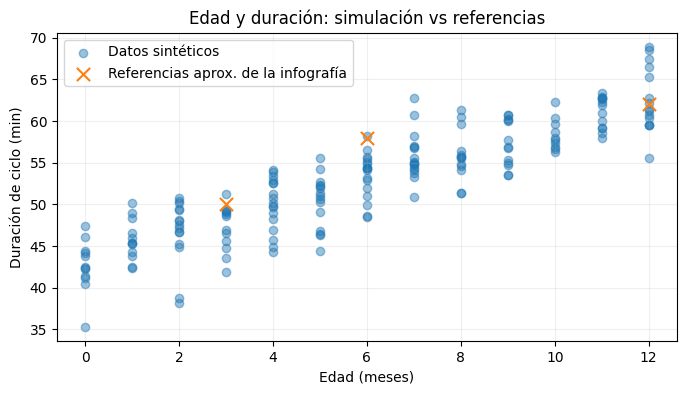

In [2]:
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(df.edad_meses,df.duracion_ciclo_min,alpha=.45,label="Datos sintéticos")
ax.scatter([3,6,12],[50,58,62],marker="x",s=90,label="Referencias aprox. de la infografía")
ax.set(xlabel="Edad (meses)",ylabel="Duración de ciclo (min)",title="Edad y duración: simulación vs referencias")
ax.legend();ax.grid(alpha=.2);plt.show()

## Entrenamiento / prueba
Separa primero 80 % de casos para entrenamiento y 20 % para prueba con `random_state=42`. Ajusta `LinearRegression()` solo en el conjunto de entrenamiento.

In [3]:
columnas=["edad_meses","lactancia","actividad_motora_0_10","despertares_noche"]
X=df[columnas];y=df["duracion_ciclo_min"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
modelo=LinearRegression()
modelo.fit(X_train,y_train)
y_pred=modelo.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mean_squared_error(y_test,y_pred))
r2=r2_score(y_test,y_pred)
print("Entrenamiento:",len(X_train),"| Prueba:",len(X_test))
print(f"MAE: {mae:.2f} min | RMSE: {rmse:.2f} min | R²: {r2:.3f}")
print("Intercepto:",round(modelo.intercept_,3))
print("Coeficientes por variable:",pd.Series(modelo.coef_,index=columnas).round(3))

Entrenamiento: 144 | Prueba: 36
MAE: 2.81 min | RMSE: 3.47 min | R²: 0.731
Intercepto: 44.785
Coeficientes por variable: edad_meses               1.602
lactancia                0.523
actividad_motora_0_10   -0.368
despertares_noche        0.023
dtype: float64


## Gráficos interpretativos
1. **Observado vs predicho**: los puntos cercanos a la diagonal indican menor diferencia.
2. **Residuos**: muestran errores de predicción; se espera dispersión alrededor de cero.

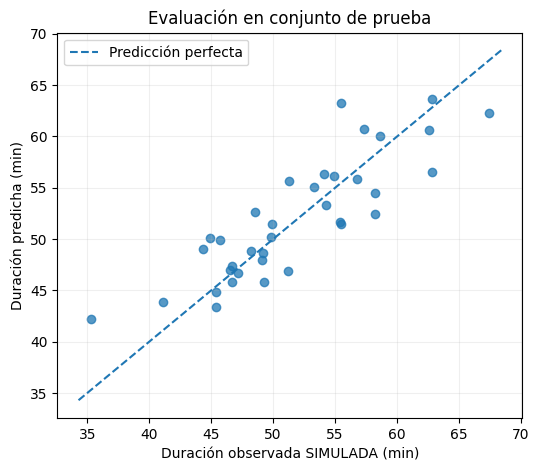

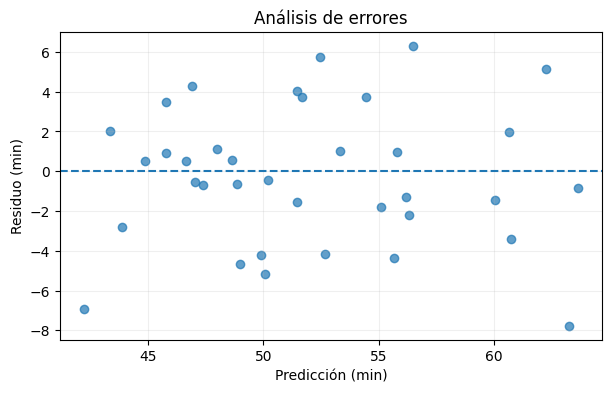

In [4]:
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(y_test,y_pred,alpha=.75)
limites=[min(y_test.min(),y_pred.min())-1,max(y_test.max(),y_pred.max())+1]
ax.plot(limites,limites,linestyle="--",label="Predicción perfecta")
ax.set(xlabel="Duración observada SIMULADA (min)",ylabel="Duración predicha (min)",title="Evaluación en conjunto de prueba")
ax.legend();ax.grid(alpha=.2);plt.show()
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(y_pred,y_test-y_pred,alpha=.7)
ax.axhline(0,linestyle="--")
ax.set(xlabel="Predicción (min)",ylabel="Residuo (min)",title="Análisis de errores")
ax.grid(alpha=.2);plt.show()

## Predicción para un ejemplo ficticio
Ejemplo hipotético (no diagnóstico): bebé de 6 meses, lactancia=1, actividad=5 y 4 despertares nocturnos.

In [5]:
ejemplo=pd.DataFrame([{ "edad_meses":6,"lactancia":1,"actividad_motora_0_10":5,"despertares_noche":4}])
print(f"Duración estimada (SIMULACIÓN): {modelo.predict(ejemplo)[0]:.1f} minutos")
print("Interpretación: aproximación académica, no consejo clínico")

Duración estimada (SIMULACIÓN): 53.2 minutos
Interpretación: aproximación académica, no consejo clínico


## Sustento del modelo y limitaciones
La regresión lineal predice una cantidad continua y permite interpretar los coeficientes del ajuste. MAE y RMSE cuantifican los errores en minutos; R² indica ajuste relativo a una referencia constante. Como los datos fueron generados usando una relación casi lineal, es esperable obtener un ajuste razonable: **esto no demuestra capacidad predictiva sobre bebés reales**. Se necesitarían registros reales anonimizados, permisos, evaluación por grupos/tiempo y revisión especializada antes de cualquier uso aplicado.